#Cell 1 — Clone repository

In [ ]:
from pathlib import Path
import subprocess

REPO_ROOT = Path("/content/CAP6411-Adaptive-Token-Merging")
REPO_URL = "https://github.com/FaramarzAboutalebi/CAP6411-Adaptive-Token-Merging.git"
BRANCH = "main"

if not REPO_ROOT.exists():
    subprocess.run(
        [
            "git", "clone", "--branch", BRANCH, "--single-branch",
            REPO_URL, str(REPO_ROOT),
        ],
        check=True,
    )
else:
    if not (REPO_ROOT / ".git").is_dir():
        raise RuntimeError(
            f"Refusing to update {REPO_ROOT}: it is not a Git repository"
        )

    status = subprocess.check_output(
        ["git", "-C", str(REPO_ROOT), "status", "--porcelain"],
        text=True,
    )
    if status.strip():
        raise RuntimeError(
            "Refusing to update the existing repository because it contains "
            "uncommitted or untracked changes. Commit, stash, or remove them "
            "before rerunning this cell."
        )

    try:
        subprocess.run(
            ["git", "-C", str(REPO_ROOT), "fetch", "origin", BRANCH],
            check=True,
        )
        local_main = subprocess.run(
            [
                "git", "-C", str(REPO_ROOT), "show-ref", "--verify",
                "--quiet", "refs/heads/main",
            ]
        )
        if local_main.returncode == 0:
            subprocess.run(
                ["git", "-C", str(REPO_ROOT), "checkout", BRANCH],
                check=True,
            )
        else:
            subprocess.run(
                [
                    "git", "-C", str(REPO_ROOT), "checkout", "-b", BRANCH,
                    "--track", f"origin/{BRANCH}",
                ],
                check=True,
            )
        subprocess.run(
            [
                "git", "-C", str(REPO_ROOT), "merge", "--ff-only",
                f"origin/{BRANCH}",
            ],
            check=True,
        )
    except subprocess.CalledProcessError as error:
        raise RuntimeError(
            "The existing repository could not be updated safely to "
            "origin/main. Resolve its branch/history state manually; no reset "
            "or local-change discard was attempted."
        ) from error

actual_branch = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "branch", "--show-current"],
    text=True,
).strip()
actual_commit = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"],
    text=True,
).strip()

print("Branch:", actual_branch)
print("Commit:", actual_commit)
assert actual_branch == BRANCH, f"Expected {BRANCH}, found {actual_branch}"

%cd /content/CAP6411-Adaptive-Token-Merging


#Cell 2 — Install dependencies

In [2]:
%pip install -q -r requirements.txt
%pip install -q -e . --no-deps

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for cap6411-adaptive-token-merging (pyproject.toml) ... done


#Cell 3 — Verify environment

In [3]:
import sys
from pathlib import Path

# Make the local package importable.
SRC_DIR = Path("/content/CAP6411-Adaptive-Token-Merging/src")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import torch
import cap6411_atm

print("Package imported successfully!")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("Project root:", cap6411_atm.PROJECT_ROOT)

Package imported successfully!
PyTorch: 2.14.1+cu130
CUDA: True
GPU: Tesla T4
Project root: /content/CAP6411-Adaptive-Token-Merging


#Cell 4

In [4]:

import subprocess
from pathlib import Path

DINO_ROOT = Path("/content/dinov3")
DINO_COMMIT = "6876159a11b4df116f30f667f8c9888617df0751"

if not DINO_ROOT.exists():
    subprocess.run([
        "git", "clone", "https://github.com/facebookresearch/dinov3.git",
        str(DINO_ROOT)
    ], check=True)

subprocess.run([
    "git", "-C", str(DINO_ROOT), "checkout", "--detach", DINO_COMMIT
], check=True)

actual = subprocess.check_output([
    "git", "-C", str(DINO_ROOT), "rev-parse", "HEAD"
], text=True).strip()

print("DINOv3 source:", DINO_ROOT)
print("Commit:", actual)
assert actual == DINO_COMMIT
print("Official DINOv3 source verified!")


DINOv3 source: /content/dinov3
Commit: 6876159a11b4df116f30f667f8c9888617df0751
Official DINOv3 source verified!


#Cell 5 — Install DINOv3

In [5]:

%pip install -q -e /content/dinov3 --no-deps
%pip install -q ftfy omegaconf regex scikit-learn submitit termcolor torchmetrics

import dinov3
print("DINOv3 imported successfully!")


  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for dinov3 (pyproject.toml) ... done
DINOv3 imported successfully!


#Cell 6 - Verify DINOv3 architecture

In [8]:

import sys
import importlib
from pathlib import Path

DINO_ROOT = Path("/content/dinov3")

# Make the official source package importable.
if str(DINO_ROOT) in sys.path:
    sys.path.remove(str(DINO_ROOT))
sys.path.insert(0, str(DINO_ROOT))

# Clear the incorrectly imported namespace package.
for name in list(sys.modules):
    if name == "dinov3" or name.startswith("dinov3."):
        del sys.modules[name]

importlib.invalidate_caches()

import dinov3
from dinov3.hub.backbones import dinov3_vitb16

print("DINOv3 location:", dinov3.__file__)
print("Official backbone imported successfully!")


DINOv3 location: /content/dinov3/dinov3/__init__.py
Official backbone imported successfully!


In [9]:

import torch

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    pretrained=False
)

print("Embedding dimension:", backbone.embed_dim)
print("Transformer blocks:", backbone.n_blocks)
print("Patch size:", backbone.patch_size)
print("Storage tokens:", backbone.n_storage_tokens)

assert backbone.embed_dim == 768
assert backbone.n_blocks == 12
assert backbone.patch_size == 16
assert backbone.n_storage_tokens == 4

print("DINOv3 architecture verified!")

del backbone


Embedding dimension: 768
Transformer blocks: 12
Patch size: 16
Storage tokens: 4
DINOv3 architecture verified!


#Cell 7 - Test the complete segmentation model

In [10]:

import torch
from cap6411_atm.models.dinov3_segmentation import (
    BraTSDINOv3Segmenter,
)

# Use a randomly initialized backbone for this structural test.
backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    pretrained=False,
)

model = BraTSDINOv3Segmenter(backbone).to("cuda")
model.eval()

images = torch.randn(1, 4, 240, 240, device="cuda")

# Check feature extraction and segmentation output.
with torch.inference_mode():
    features = model.extract_features(images)
    logits = model.decode_features(features)

print("Input:", tuple(images.shape))
print("Features:", [tuple(f.shape) for f in features])
print("Logits:", tuple(logits.shape))
print("Finite logits:", torch.isfinite(logits).all().item())

assert all(f.shape == (1, 768, 15, 15) for f in features)
assert logits.shape == (1, 3, 240, 240)
assert torch.isfinite(logits).all()

print("Full segmentation forward pass verified!")

del model, backbone, images, features, logits
torch.cuda.empty_cache()


Input: (1, 4, 240, 240)
Features: [(1, 768, 15, 15), (1, 768, 15, 15), (1, 768, 15, 15), (1, 768, 15, 15)]
Logits: (1, 3, 240, 240)
Finite logits: True
Full segmentation forward pass verified!


#Cell 8 - Test backward gradients and GPU memory



In [11]:

import torch
from torch import nn
from cap6411_atm.models.dinov3_segmentation import BraTSDINOv3Segmenter

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    pretrained=False
)

model = BraTSDINOv3Segmenter(backbone).cuda()
model.train()

images = torch.randn(1, 4, 240, 240, device="cuda")
targets = torch.randint(
    0, 2, (1, 3, 240, 240), device="cuda"
).float()

optimizer = torch.optim.AdamW(
    list(model.adapter.parameters()) +
    list(model.decoder.parameters()),
    lr=1e-4
)

optimizer.zero_grad(set_to_none=True)

with torch.autocast("cuda", dtype=torch.float16):
    logits = model(images)
    loss = nn.functional.binary_cross_entropy_with_logits(
        logits.float(), targets
    )

loss.backward()

adapter_grad = any(
    p.grad is not None and torch.isfinite(p.grad).all().item()
    for p in model.adapter.parameters()
)
decoder_grad = any(
    p.grad is not None and torch.isfinite(p.grad).all().item()
    for p in model.decoder.parameters()
)
backbone_grad = any(
    p.grad is not None
    for p in model.encoder.backbone.parameters()
)

print("Loss:", loss.item())
print("Adapter gradients:", adapter_grad)
print("Decoder gradients:", decoder_grad)
print("Backbone gradients:", backbone_grad)
print("Peak GPU memory (GiB):",
      round(torch.cuda.max_memory_allocated() / 1024**3, 2))

assert torch.isfinite(loss)
assert adapter_grad and decoder_grad
assert not backbone_grad

print("Backward-pass verification successful!")

del model, backbone, images, targets, logits, loss, optimizer
torch.cuda.empty_cache()


Loss: 0.7209580540657043
Adapter gradients: True
Decoder gradients: True
Backbone gradients: False
Peak GPU memory (GiB): 0.64
Backward-pass verification successful!


#Cell 9 - Mount Google Drive in Colab

In [12]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

CHECKPOINT = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth"
)

print("Checkpoint exists:", CHECKPOINT.is_file())

if CHECKPOINT.is_file():
    print("Checkpoint size (MB):",
          round(CHECKPOINT.stat().st_size / 1024**2, 2))

assert CHECKPOINT.is_file(), "Checkpoint not found!"
print("Checkpoint located successfully!")


Mounted at /content/drive
Checkpoint exists: True
Checkpoint size (MB): 326.98
Checkpoint located successfully!


#Cell 10 - Load the real pretrained DINOv3 weights

In [13]:

# Cell 10 - Load official pretrained DINOv3 weights

import torch

assert CHECKPOINT.is_file()

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    weights=str(CHECKPOINT),
    check_hash=True
)

print("Pretrained checkpoint loaded successfully!")
print("Embedding dimension:", backbone.embed_dim)
print("Transformer blocks:", backbone.n_blocks)
print("Patch size:", backbone.patch_size)
print("Storage tokens:", backbone.n_storage_tokens)

assert backbone.embed_dim == 768
assert backbone.n_blocks == 12
assert backbone.patch_size == 16
assert backbone.n_storage_tokens == 4

print("Official pretrained DINOv3 architecture verified!")

del backbone


Downloading: "file:///content/drive/MyDrive/CAP6411/checkpoints/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth


100%|██████████| 327M/327M [00:04<00:00, 70.8MB/s]


Pretrained checkpoint loaded successfully!
Embedding dimension: 768
Transformer blocks: 12
Patch size: 16
Storage tokens: 4
Official pretrained DINOv3 architecture verified!


# Cell 11 - Test pretrained BraTS segmentation model


In [18]:

# Cell 11 - Test pretrained BraTS segmentation model

import torch
from cap6411_atm.models.dinov3_segmentation import BraTSDINOv3Segmenter

torch.cuda.empty_cache()

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    weights=str(CHECKPOINT),
    check_hash=True
)

model = BraTSDINOv3Segmenter(backbone).cuda()
model.eval()

images = torch.randn(1, 4, 240, 240, device="cuda")

with torch.inference_mode():
    logits = model(images)

print("Input:", tuple(images.shape))
print("Output:", tuple(logits.shape))
print("Finite output:", torch.isfinite(logits).all().item())
print("Backbone frozen:", all(
    not p.requires_grad
    for p in model.encoder.backbone.parameters()
))

assert logits.shape == (1, 3, 240, 240)
assert torch.isfinite(logits).all()
assert all(
    not p.requires_grad
    for p in model.encoder.backbone.parameters()
)

print("Pretrained segmentation forward pass verified!")

del model, backbone, images, logits
torch.cuda.empty_cache()


Input: (1, 4, 240, 240)
Output: (1, 3, 240, 240)
Finite output: True
Backbone frozen: True
Pretrained segmentation forward pass verified!


# Cell 12 - Verify pretrained-model gradients and GPU memory


In [19]:

# Cell 12 - Verify pretrained-model gradients and GPU memory

import torch
import torch.nn.functional as F

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    weights=str(CHECKPOINT),
    check_hash=True
)

model = BraTSDINOv3Segmenter(backbone).cuda()
model.train()

images = torch.randn(1, 4, 240, 240, device="cuda")
targets = torch.randint(
    0, 2, (1, 3, 240, 240), device="cuda"
).float()

with torch.autocast("cuda", dtype=torch.float16):
    logits = model(images)
    loss = F.binary_cross_entropy_with_logits(
        logits.float(), targets
    )

loss.backward()

adapter_grad = any(
    p.grad is not None and torch.isfinite(p.grad).all().item()
    for p in model.adapter.parameters()
)

decoder_grad = any(
    p.grad is not None and torch.isfinite(p.grad).all().item()
    for p in model.decoder.parameters()
)

backbone_grad = any(
    p.grad is not None
    for p in model.encoder.backbone.parameters()
)

print("Loss:", loss.item())
print("Adapter gradients:", adapter_grad)
print("Decoder gradients:", decoder_grad)
print("Backbone gradients:", backbone_grad)
print("Peak GPU memory (GiB):",
      round(torch.cuda.max_memory_allocated() / 1024**3, 2))

assert torch.isfinite(loss)
assert adapter_grad and decoder_grad
assert not backbone_grad

print("Pretrained backward-pass verification successful!")

del model, backbone, images, targets, logits, loss
torch.cuda.empty_cache()


Loss: 0.7056060433387756
Adapter gradients: True
Decoder gradients: True
Backbone gradients: False
Peak GPU memory (GiB): 0.65
Pretrained backward-pass verification successful!


# Cell 13 - Verify BraTS dataset in Google Colab


In [20]:

# Cell 13 - Verify BraTS dataset in Google Colab

from pathlib import Path
import hashlib

BRATS_ZIP = Path(
    "/content/drive/MyDrive/CAP6411/datasets/"
    "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData.zip"
)

EXPECTED_SIZE = 13_172_616_844
EXPECTED_SHA256 = (
    "e1f6b0ff1320dcf2fc1d472cdf823190446783701f2dd705ac3b4c14a2a97d3f"
)

assert BRATS_ZIP.is_file(), "BraTS dataset not found!"

actual_size = BRATS_ZIP.stat().st_size
print("Dataset exists:", True)
print("Size (bytes):", actual_size)
assert actual_size == EXPECTED_SIZE, "Dataset size mismatch!"

sha256 = hashlib.sha256()
with BRATS_ZIP.open("rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

actual_hash = sha256.hexdigest()
print("SHA-256:", actual_hash)
assert actual_hash == EXPECTED_SHA256, "Dataset checksum mismatch!"

print("BraTS dataset verified successfully!")


Dataset exists: True
Size (bytes): 13172616844
SHA-256: e1f6b0ff1320dcf2fc1d472cdf823190446783701f2dd705ac3b4c14a2a97d3f
BraTS dataset verified successfully!


# Cell 14 - Inspect BraTS ZIP structure


In [22]:

# Cell 14 - Inspect BraTS ZIP structure

import zipfile
from collections import Counter

with zipfile.ZipFile(BRATS_ZIP, "r") as archive:
    files = [f for f in archive.namelist()
             if f.endswith(".nii.gz")]

    patients = {
        name.split("/")[-2]
        for name in files
    }

    print("MRI/segmentation files:", len(files))
    print("Unique patient folders:", len(patients))
    print("\nExample files:")
    for name in files[:5]:
        print(name)

    assert len(patients) == 1251
    assert len(files) == 1251 * 5

print("\nBraTS ZIP structure verified!")


MRI/segmentation files: 6255
Unique patient folders: 1251

Example files:
ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00324-000/BraTS-GLI-00324-000-t1c.nii.gz
ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00324-000/BraTS-GLI-00324-000-t2w.nii.gz
ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00324-000/BraTS-GLI-00324-000-t1n.nii.gz
ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00324-000/BraTS-GLI-00324-000-t2f.nii.gz
ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00324-000/BraTS-GLI-00324-000-seg.nii.gz

BraTS ZIP structure verified!


# Cell 15 - Inspect the existing BraTS dataset loader


In [24]:

# Cell 15 - Find the actual BraTS dataset module

import cap6411_atm.data as data
import pkgutil
import inspect
from pathlib import Path

print("Data package location:", list(data.__path__))

print("\nAvailable modules:")
for module in pkgutil.iter_modules(data.__path__):
    print(" -", module.name)

print("\nPython files:")
for path in sorted(Path(list(data.__path__)[0]).rglob("*.py")):
    print(" -", path.relative_to(Path(list(data.__path__)[0])))


Data package location: ['/content/CAP6411-Adaptive-Token-Merging/src/cap6411_atm/data']

Available modules:
 - dataset
 - inspection
 - splitting

Python files:
 - __init__.py
 - dataset.py
 - inspection.py
 - splitting.py


In [25]:

# Cell 15 - Inspect the actual BraTS dataset loader

import inspect
import cap6411_atm.data.dataset as dataset

for name, obj in inspect.getmembers(dataset, inspect.isclass):
    if obj.__module__ == dataset.__name__:
        print(f"{name}{inspect.signature(obj)}")


BraTSAxialSliceDataset(archive_path: 'str | Path', manifest_path: 'str | Path', split: 'str', inspection_config: 'str | Path | InspectionConfig', *, slice_indices: 'Sequence[int] | Mapping[str, Sequence[int]] | None' = None, normalization: 'NormalizationConfig' = NormalizationConfig(epsilon=1e-08), cache_dir: 'str | Path | None' = None, max_cached_patients: 'int' = 1) -> 'None'
NormalizationConfig(epsilon: 'float' = 1e-08) -> None


# Cell 16 - Find the existing split-generation functions


In [26]:

# Cell 16 - Find the existing split-generation functions

import inspect
from cap6411_atm.data import splitting, inspection

for module in [splitting, inspection]:
    print(f"\n{module.__name__}")

    for name, obj in inspect.getmembers(module):
        if (
            (inspect.isfunction(obj) or inspect.isclass(obj))
            and getattr(obj, "__module__", None) == module.__name__
        ):
            print(f"  {name}{inspect.signature(obj)}")



cap6411_atm.data.splitting
  SplitConfig(seed: 'int' = 42, percentages: 'Mapping[str, float]' = <factory>) -> None
  _build_parser() -> 'argparse.ArgumentParser'
  allocate_split_counts(total: 'int', percentages: 'Mapping[str, float]') -> 'dict[str, int]'
  build_manifest_from_archive(archive: 'str | Path', inspection_config: 'InspectionConfig', *, split_config: 'SplitConfig' = SplitConfig(seed=42, percentages={'train': 0.7, 'validation': 0.15, 'test': 0.15}), dataset_name: 'str', dataset_source: 'str', expected_patient_count: 'int | None' = None) -> 'dict[str, Any]'
  build_split_manifest(patient_ids: 'Iterable[str]', *, split_config: 'SplitConfig' = SplitConfig(seed=42, percentages={'train': 0.7, 'validation': 0.15, 'test': 0.15}), dataset_name: 'str', dataset_source: 'str', archive: 'str | Path | None' = None, generated_at_utc: 'str | None' = None) -> 'dict[str, Any]'
  load_csv_manifest(path: 'str | Path') -> 'dict[str, list[str]]'
  load_json_manifest(path: 'str | Path') -> 'dict

# Cell 17 - Generate reproducible BraTS patient splits


In [27]:

# Cell 17 - Generate reproducible BraTS patient splits

from pathlib import Path
from cap6411_atm.data.splitting import (
    SplitConfig,
    build_manifest_from_archive,
    write_json_manifest,
    validate_splits,
)
from cap6411_atm.data.inspection import InspectionConfig

inspection_config = InspectionConfig(
    file_suffixes={
        "t1n": "-t1n.nii.gz",
        "t1c": "-t1c.nii.gz",
        "t2w": "-t2w.nii.gz",
        "t2f": "-t2f.nii.gz",
        "segmentation": "-seg.nii.gz",
    },
    expected_shape=(240, 240, 155),
    expected_spacing=(1.0, 1.0, 1.0),
    allowed_segmentation_labels=(0, 1, 2, 3),
)

split_config = SplitConfig(
    seed=42,
    percentages={
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
    },
)

manifest = build_manifest_from_archive(
    BRATS_ZIP,
    inspection_config,
    split_config=split_config,
    dataset_name="BraTS 2023 Adult Glioma",
    dataset_source="ASNR-MICCAI BraTS 2023 GLI TrainingData",
    expected_patient_count=1251,
)

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/CAP6411/"
    "brats2023_gli_split_seed42.json"
)

write_json_manifest(manifest, MANIFEST_PATH)

print("Manifest saved:", MANIFEST_PATH)
print("Manifest keys:", list(manifest.keys()))

splits = manifest["splits"]

for name, patients in splits.items():
    print(f"{name}: {len(patients)} patients")

print("Validation:", validate_splits(splits))

assert len(splits["train"]) == 876
assert len(splits["validation"]) == 187
assert len(splits["test"]) == 188

print("Patient-level split generated successfully!")


Manifest saved: /content/drive/MyDrive/CAP6411/brats2023_gli_split_seed42.json
Manifest keys: ['schema_version', 'dataset', 'generation', 'split_percentages', 'patient_counts', 'total_patients', 'validation', 'splits']
train: 876 patients
validation: 187 patients
test: 188 patients
Validation: {'unique_within_splits': True, 'sets_disjoint': True, 'complete_patient_coverage': True}
Patient-level split generated successfully!


# Cell 18 - Load the first real BraTS MRI slice


In [29]:

# Cell 18 - Load first real BraTS MRI slice (corrected)

from cap6411_atm.data.dataset import BraTSAxialSliceDataset
from cap6411_atm.data.inspection import InspectionConfig
import torch

# Map the loader's internal names to BraTS 2023 filenames.
loader_config = InspectionConfig(
    file_suffixes={
        "t1": "-t1n.nii.gz",
        "t1ce": "-t1c.nii.gz",
        "t2": "-t2w.nii.gz",
        "flair": "-t2f.nii.gz",
        "segmentation": "-seg.nii.gz",
    },
    expected_shape=(240, 240, 155),
    expected_spacing=(1.0, 1.0, 1.0),
    allowed_segmentation_labels=(0, 1, 2, 3),
)

train_dataset = BraTSAxialSliceDataset(
    archive_path=BRATS_ZIP,
    manifest_path=MANIFEST_PATH,
    split="train",
    inspection_config=loader_config,
    slice_indices=[77],
    max_cached_patients=1,
)

sample = train_dataset[0]

print("Dataset length:", len(train_dataset))
print("Sample keys:", list(sample.keys()))

for key, value in sample.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
    else:
        print(f"{key}: {value}")

print("Real BraTS slice loaded successfully!")


Dataset length: 876
Sample keys: ['image', 'target', 'patient_id', 'slice_index', 'split']
image: shape=(4, 240, 240), dtype=torch.float32
target: shape=(3, 240, 240), dtype=torch.float32
patient_id: BraTS-GLI-01299-000
slice_index: 77
split: train
Real BraTS slice loaded successfully!


# Cell 19 - Visualize real BraTS MRI and segmentation masks


In [30]:

# Cell 19 - Visualize real BraTS MRI and segmentation masks

import matplotlib.pyplot as plt
import torch

images = sample["image"].cpu()
targets = sample["target"].cpu()

assert images.shape == (4, 240, 240)
assert targets.shape == (3, 240, 240)
assert torch.isfinite(images).all()
assert torch.isfinite(targets).all()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

modalities = ["T1", "T1ce", "T2", "FLAIR"]
regions = ["Whole Tumor", "Tumor Core", "Enhancing Tumor"]

for i in range(4):
    axes[0, i].imshow(images[i], cmap="gray")
    axes[0, i].set_title(modalities[i])
    axes[0, i].axis("off")

for i in range(3):
    axes[1, i].imshow(targets[i], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(regions[i])
    axes[1, i].axis("off")

axes[1, 3].axis("off")

plt.suptitle(
    f"BraTS 2023 — {sample['patient_id']} — Slice {sample['slice_index']}"
)
plt.tight_layout()
plt.show()

print("Image finite:", torch.isfinite(images).all().item())
print("Target finite:", torch.isfinite(targets).all().item())
print("Target unique values:", torch.unique(targets).tolist())
print("Tumor pixels (WT, TC, ET):",
      [int(t.sum()) for t in targets])

assert set(torch.unique(targets).tolist()).issubset({0.0, 1.0})
assert torch.all(targets[2] <= targets[1])
assert torch.all(targets[1] <= targets[0])

print("Real BraTS image and mask checks passed!")


Image finite: True
Target finite: True
Target unique values: [0.0, 1.0]
Tumor pixels (WT, TC, ET): [3012, 271, 259]
Real BraTS image and mask checks passed!


# Cell 20 - Real BraTS MRI forward-pass test


In [31]:

# Cell 20 - Real BraTS MRI forward-pass test

import torch
from cap6411_atm.models.dinov3_segmentation import BraTSDINOv3Segmenter

backbone = torch.hub.load(
    "/content/dinov3",
    "dinov3_vitb16",
    source="local",
    weights=str(CHECKPOINT),
    check_hash=True,
)

model = BraTSDINOv3Segmenter(backbone).cuda()
model.eval()

real_image = sample["image"].unsqueeze(0).cuda()
real_target = sample["target"].unsqueeze(0).cuda()

with torch.inference_mode():
    logits = model(real_image)
    probabilities = torch.sigmoid(logits)

print("MRI input:", tuple(real_image.shape))
print("Ground truth:", tuple(real_target.shape))
print("Model output:", tuple(logits.shape))
print("Finite predictions:", torch.isfinite(probabilities).all().item())
print("Probability range:",
      round(probabilities.min().item(), 4),
      round(probabilities.max().item(), 4))

assert logits.shape == real_target.shape
assert torch.isfinite(probabilities).all()

print("Real BraTS pretrained forward pass successful!")

del model, backbone, real_image, real_target, logits, probabilities
torch.cuda.empty_cache()


MRI input: (1, 4, 240, 240)
Ground truth: (1, 3, 240, 240)
Model output: (1, 3, 240, 240)
Finite predictions: True
Probability range: 0.2732 0.6637
Real BraTS pretrained forward pass successful!


# Cell 21 - Inspect existing training files


In [32]:

# Cell 21 - Inspect existing training files

from pathlib import Path

root = Path("/content/CAP6411-Adaptive-Token-Merging")

for folder in ["configs", "scripts", "src/cap6411_atm", "notebooks"]:
    path = root / folder
    print(f"\n{folder}/")

    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file() and file.suffix in {
                ".py", ".json", ".yaml", ".yml", ".ipynb"
            }:
                print(" -", file.relative_to(root))
    else:
        print(" (not present)")



configs/
 - configs/brats2023_gli_inspection.json
 - configs/dinov3_vitb16_brats.json

scripts/
 (not present)

src/cap6411_atm/
 - src/cap6411_atm/__init__.py
 - src/cap6411_atm/benchmark/__init__.py
 - src/cap6411_atm/data/__init__.py
 - src/cap6411_atm/data/dataset.py
 - src/cap6411_atm/data/inspection.py
 - src/cap6411_atm/data/splitting.py
 - src/cap6411_atm/evaluation/__init__.py
 - src/cap6411_atm/merging/__init__.py
 - src/cap6411_atm/models/__init__.py
 - src/cap6411_atm/models/dinov3_segmentation.py
 - src/cap6411_atm/project.py

notebooks/
 - notebooks/01_baseline.ipynb
 - notebooks/02_token_merging.ipynb
 - notebooks/03_efficiency.ipynb
 - notebooks/04_evaluation.ipynb


# Cell 22 - Inspect the existing baseline configuration


In [33]:

# Cell 22 - Inspect the existing baseline configuration

import json
from pathlib import Path

config_path = Path(
    "/content/CAP6411-Adaptive-Token-Merging/"
    "configs/dinov3_vitb16_brats.json"
)

with config_path.open() as f:
    config = json.load(f)

print(json.dumps(config, indent=2))


{
  "checkpoint_filename": "dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth",
  "decoder_channels": [
    128,
    96,
    64,
    32
  ],
  "dinov3_revision": "6876159a11b4df116f30f667f8c9888617df0751",
  "embedding_dim": 768,
  "encoder_channels": 3,
  "feature_blocks": [
    2,
    5,
    8,
    11
  ],
  "input_channels": 4,
  "input_size": [
    240,
    240
  ],
  "lateral_channels": 128,
  "output_channels": 3,
  "patch_size": 16,
  "storage_tokens": 4,
  "transformer_blocks": 12
}


# Cell 23 - Update repository to the training commit


In [34]:

# Cell 23 - Update repository to the training commit

from pathlib import Path
import subprocess

REPO_ROOT = Path("/content/CAP6411-Adaptive-Token-Merging")

EXPECTED_COMMIT = (
    "78f38f071455174811744eb5a5e3094118d4e068"
)

subprocess.run(
    ["git", "-C", str(REPO_ROOT), "fetch", "origin",
     "feature/brats-dataset-inspection"],
    check=True
)

subprocess.run(
    ["git", "-C", str(REPO_ROOT), "checkout",
     "--detach", EXPECTED_COMMIT],
    check=True
)

actual_commit = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"],
    text=True
).strip()

assert actual_commit == EXPECTED_COMMIT

training_config = (
    REPO_ROOT / "configs/brats2023_gli_baseline_training.json"
)

assert training_config.is_file()

print("Commit:", actual_commit)
print("Training configuration found:", training_config.is_file())
print("Repository update successful!")


Commit: 78f38f071455174811744eb5a5e3094118d4e068
Training configuration found: True
Repository update successful!


# Cell 24 - Real BraTS training smoke test


In [35]:

# Cell 24 - Real BraTS training smoke test

import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-m", "cap6411_atm.training.baseline",
        "--config",
        "configs/brats2023_gli_baseline_training.json",
        "--smoke-test",
    ],
    cwd="/content/CAP6411-Adaptive-Token-Merging",
    check=True,
)

print("Training smoke test completed successfully!")


Training smoke test completed successfully!


# Cell 25 - Capture real BraTS training smoke-test metrics


In [36]:

# Cell 25 - Capture real BraTS training smoke-test metrics

import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-m", "cap6411_atm.training.baseline",
        "--config",
        "configs/brats2023_gli_baseline_training.json",
        "--smoke-test",
    ],
    cwd="/content/CAP6411-Adaptive-Token-Merging",
    capture_output=True,
    text=True,
)

print("=== STDOUT ===")
print(result.stdout)

print("=== STDERR ===")
print(result.stderr)

print("Exit code:", result.returncode)

assert result.returncode == 0, "Smoke test failed"


=== STDOUT ===
{
  "status": "passed",
  "scope": "pilot",
  "warning": "smoke test performs one optimizer update; rebuild before full training",
  "loss": 0.7744264602661133,
  "image_shape": [
    2,
    4,
    240,
    240
  ],
  "target_shape": [
    2,
    3,
    240,
    240
  ],
  "logit_shape": [
    2,
    3,
    240,
    240
  ],
  "batch_samples": 2,
  "elapsed_seconds": 0.9762519289997726,
  "samples_per_second": 2.048651521794295,
  "device": "cuda",
  "amp_enabled": true,
  "peak_cuda_bytes": 815359488
}

=== STDERR ===

Exit code: 0


# Cell 26 - Run real BraTS pilot training


In [37]:

# Cell 26 - Run real BraTS pilot training

import subprocess
import sys

command = [
    sys.executable,
    "-m", "cap6411_atm.training.baseline",
    "--config",
    "configs/brats2023_gli_baseline_training.json",
]

print("Starting BraTS pilot training...", flush=True)

result = subprocess.run(
    command,
    cwd="/content/CAP6411-Adaptive-Token-Merging",
    check=True,
)

print("Pilot training completed successfully!")


Starting BraTS pilot training...
Pilot training completed successfully!


# Cell 27 - Inspect completed pilot training history


In [38]:

# Cell 27 - Inspect completed pilot training history

import json
from pathlib import Path

history_path = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_brats_baseline/history.json"
)

history = json.loads(history_path.read_text())

print("History type:", type(history).__name__)

if isinstance(history, list):
    print("Recorded epochs:", len(history))
    print("\nFirst epoch:")
    print(json.dumps(history[0], indent=2))
    print("\nFinal epoch:")
    print(json.dumps(history[-1], indent=2))

elif isinstance(history, dict):
    print("History keys:", list(history.keys()))
    print("\nLatest recorded results:")
    print(json.dumps(history, indent=2)[-6000:])


History type: list
Recorded epochs: 30

First epoch:
{
  "epoch": 0,
  "scope": "pilot",
  "pilot_metrics": true,
  "metrics_scope": "deterministic_patient_subset",
  "train": {
    "loss": 0.41878777282132257,
    "bce_loss": 0.04840830370230833,
    "dice_loss": 0.7891672428577177,
    "samples": 1240,
    "batches": 624,
    "elapsed_seconds": 56.69454766400122,
    "samples_per_second": 21.871591733103298,
    "estimated_full_epoch_seconds": 6208.052969208134
  },
  "validation": {
    "dice": {
      "WT": 0.6639124931553261,
      "TC": 0.5939912111247926,
      "ET": 0.611063193166986
    },
    "macro_dice": 0.6229889658157015,
    "all_empty": {
      "WT": false,
      "TC": false,
      "ET": false
    },
    "target_voxels": {
      "WT": 552668,
      "TC": 236765,
      "ET": 135964
    },
    "prediction_voxels": {
      "WT": 285575,
      "TC": 123008,
      "ET": 126058
    },
    "loss": 0.43196137578737354,
    "samples": 620,
    "batches": 312,
    "elapsed_second

# Cell 28 - Identify best pilot epoch and plot learning curves


Completed epochs: 30
Best epoch: 15
Best validation macro Dice: 0.7658

Best epoch per-region Dice:
  WT: 0.8575
  TC: 0.7991
  ET: 0.6407


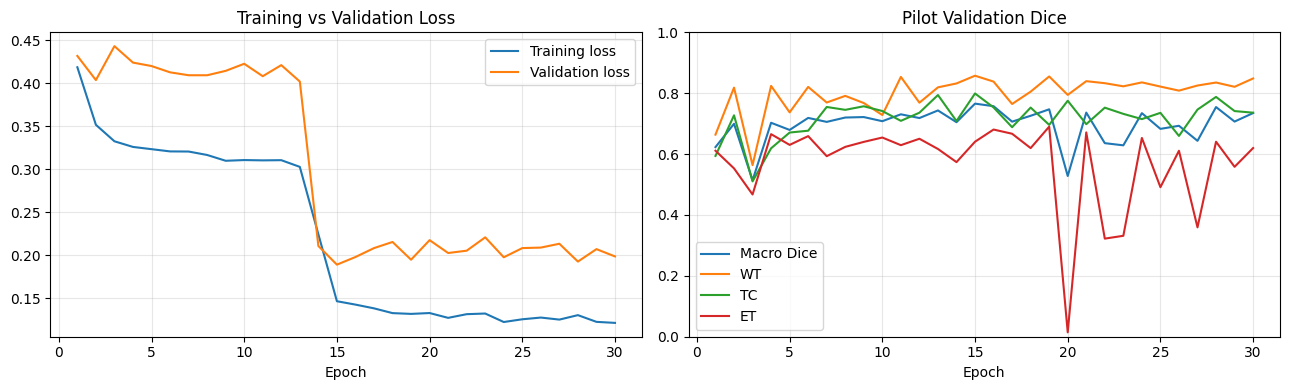

In [39]:

# Cell 28 - Identify best pilot epoch and plot learning curves

import matplotlib.pyplot as plt

best = max(history, key=lambda x: x["validation"]["macro_dice"])

print("Completed epochs:", len(history))
print("Best epoch:", best["epoch"] + 1)
print("Best validation macro Dice:",
      round(best["validation"]["macro_dice"], 4))

print("\nBest epoch per-region Dice:")
for region, score in best["validation"]["dice"].items():
    print(f"  {region}: {score:.4f}")

epochs = [h["epoch"] + 1 for h in history]
train_loss = [h["train"]["loss"] for h in history]
val_loss = [h["validation"]["loss"] for h in history]
macro_dice = [h["validation"]["macro_dice"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, train_loss, label="Training loss")
axes[0].plot(epochs, val_loss, label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, macro_dice, label="Macro Dice")
for region in ["WT", "TC", "ET"]:
    axes[1].plot(
        epochs,
        [h["validation"]["dice"][region] for h in history],
        label=region
    )

axes[1].set_title("Pilot Validation Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Cell 29 - Verify best and last checkpoint metadata


In [40]:

# Cell 29 - Verify best and last checkpoint metadata

import torch
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_brats_baseline"
)

for name in ["best.pt", "last.pt"]:
    path = checkpoint_dir / name

    assert path.is_file(), f"Missing checkpoint: {name}"

    # Load only checkpoints generated by our own trusted training code.
    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print(f"\n{name}")
    print("Size (MB):", round(path.stat().st_size / 1e6, 2))
    print("Checkpoint keys:", list(ckpt.keys()))

    for key in [
        "epoch",
        "best_validation_macro_dice",
        "best_macro_dice",
        "best_epoch"
    ]:
        if key in ckpt:
            print(f"{key}:", ckpt[key])

    del ckpt

print("\nBest epoch from history:",
      max(history, key=lambda h: h["validation"]["macro_dice"])["epoch"] + 1)



best.pt
Size (MB): 358.71
Checkpoint keys: ['schema_version', 'epoch', 'best_macro_dice', 'model_state', 'optimizer_state', 'scaler_state', 'training_config', 'model_config', 'dataset_metadata', 'history', 'rng_state', 'environment']
epoch: 14
best_macro_dice: 0.7657609535219461

last.pt
Size (MB): 358.72
Checkpoint keys: ['schema_version', 'epoch', 'best_macro_dice', 'model_state', 'optimizer_state', 'scaler_state', 'training_config', 'model_config', 'dataset_metadata', 'history', 'rng_state', 'environment']
epoch: 29
best_macro_dice: 0.7657609535219461

Best epoch from history: 15


# Cell 30 - Inspect training behavior around the loss drop


In [41]:

# Cell 30 - Inspect training behavior around the loss drop

print(
    f"{'Epoch':<7} {'Train':<9} {'BCE':<9} "
    f"{'DiceLoss':<10} {'ValLoss':<9} {'MacroDice':<10} "
    f"{'TrainN':<8} {'ValN':<8}"
)

for h in history:
    if 10 <= h["epoch"] <= 17:
        t = h["train"]
        v = h["validation"]

        print(
            f"{h['epoch'] + 1:<7} "
            f"{t['loss']:<9.4f} "
            f"{t['bce_loss']:<9.4f} "
            f"{t['dice_loss']:<10.4f} "
            f"{v['loss']:<9.4f} "
            f"{v['macro_dice']:<10.4f} "
            f"{t['samples']:<8} "
            f"{v['samples']:<8}"
        )


Epoch   Train     BCE       DiceLoss   ValLoss   MacroDice  TrainN   ValN    
11      0.3104    0.0090    0.6119     0.4084    0.7307     1240     620     
12      0.3106    0.0081    0.6131     0.4213    0.7184     1240     620     
13      0.3028    0.0082    0.5975     0.4022    0.7434     1240     620     
14      0.2244    0.0090    0.4399     0.2108    0.7048     1240     620     
15      0.1465    0.0098    0.2832     0.1891    0.7658     1240     620     
16      0.1426    0.0092    0.2759     0.1979    0.7573     1240     620     
17      0.1382    0.0083    0.2681     0.2083    0.7066     1240     620     
18      0.1327    0.0084    0.2569     0.2154    0.7259     1240     620     


# Cell 31 - Inspect actual Dice loss implementation


In [42]:

# Cell 31 - Inspect actual Dice loss implementation

import inspect
from cap6411_atm.training.losses import MultilabelBCEDiceLoss

print(inspect.getsource(MultilabelBCEDiceLoss))


class MultilabelBCEDiceLoss(nn.Module):
    """Weighted BCE-with-logits plus channel-balanced soft Dice loss.

    Dice is computed independently for WT, TC, and ET over the batch and spatial
    dimensions, then averaged. Targets are overlapping binary channels, so this
    loss intentionally uses sigmoid semantics rather than softmax.
    """

    def __init__(
        self,
        *,
        bce_weight: float = 0.5,
        dice_weight: float = 0.5,
        smooth: float = 1e-6,
    ) -> None:
        super().__init__()
        if bce_weight < 0 or dice_weight < 0 or bce_weight + dice_weight <= 0:
            raise ValueError("loss weights must be non-negative with a positive sum")
        if smooth <= 0:
            raise ValueError("smooth must be positive")
        self.bce_weight = float(bce_weight)
        self.dice_weight = float(dice_weight)
        self.smooth = float(smooth)

    def components(self, logits: Tensor, targets: Tensor) -> dict[str, Tensor]:
        if logits.

# Cell 32 - Inspect best checkpoint model metadata


In [43]:

# Cell 32 - Inspect best checkpoint model metadata

import torch

best_path = (
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_brats_baseline/best.pt"
)

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=False
)

print("Saved epoch:", checkpoint["epoch"] + 1)
print("Best macro Dice:", checkpoint["best_macro_dice"])

print("\nModel configuration:")
print(checkpoint["model_config"])

print("\nDataset metadata:")
print(checkpoint["dataset_metadata"])

print("\nModel state entries:", len(checkpoint["model_state"]))
print("First parameter names:")
for name in list(checkpoint["model_state"])[:10]:
    print(" ", name)


Saved epoch: 15
Best macro Dice: 0.7657609535219461

Model configuration:
{'input_channels': 4, 'encoder_channels': 3, 'input_size': (240, 240), 'patch_size': 16, 'embedding_dim': 768, 'transformer_blocks': 12, 'storage_tokens': 4, 'feature_blocks': (2, 5, 8, 11), 'lateral_channels': 128, 'decoder_channels': (128, 96, 64, 32), 'output_channels': 3, 'checkpoint_filename': 'dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth', 'dinov3_revision': '6876159a11b4df116f30f667f8c9888617df0751'}

Dataset metadata:
{'scope': 'pilot', 'pilot_metrics': True, 'metrics_scope': 'deterministic_patient_subset', 'train_patients': ['BraTS-GLI-01368-000', 'BraTS-GLI-00568-000', 'BraTS-GLI-00530-000', 'BraTS-GLI-00502-001', 'BraTS-GLI-01423-000', 'BraTS-GLI-01535-000', 'BraTS-GLI-00052-000', 'BraTS-GLI-00347-000'], 'validation_patients': ['BraTS-GLI-01510-000', 'BraTS-GLI-01032-000', 'BraTS-GLI-00804-000', 'BraTS-GLI-01352-000'], 'train_patient_count': 8, 'validation_patient_count': 4, 'full_train_patient_count':

# Cell 33 - Visualize trained model predictions


In [45]:

# Cell 33 - Visualize trained model predictions

import torch
import matplotlib.pyplot as plt

from cap6411_atm.models import (
    DINOv3SegmentationConfig,
    build_pretrained_brats_dinov3,
)
from cap6411_atm.data.dataset import BraTSAxialSliceDataset

# Rebuild exactly the same model architecture.
model_config = DINOv3SegmentationConfig.from_json(
    "/content/CAP6411-Adaptive-Token-Merging/"
    "configs/dinov3_vitb16_brats.json"
)

trained_model = build_pretrained_brats_dinov3(
    "/content/dinov3",
    str(CHECKPOINT),
    model_config,
)

trained_model.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

trained_model = trained_model.cuda().eval()

# Choose a patient from the pilot validation subset.
patient_id = checkpoint["dataset_metadata"]["validation_patients"][0]


# Corrected validation sample selection

visual_dataset = BraTSAxialSliceDataset(
    archive_path=BRATS_ZIP,
    manifest_path=MANIFEST_PATH,
    split="validation",
    inspection_config=loader_config,
    slice_indices=[77],
    max_cached_patients=1,
)

# Find our selected pilot validation patient.
patient_index = list(visual_dataset.patient_ids).index(patient_id)
sample_visual = visual_dataset[patient_index]

assert sample_visual["patient_id"] == patient_id
assert sample_visual["slice_index"] == 77

image = sample_visual["image"].unsqueeze(0).cuda()
target = sample_visual["target"].cpu()

with torch.inference_mode():
    logits = trained_model(image)
    prediction = (torch.sigmoid(logits) >= 0.5)[0].cpu()

regions = ["Whole Tumor", "Tumor Core", "Enhancing Tumor"]

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for i, region in enumerate(regions):
    axes[i, 0].imshow(sample_visual["image"][3], cmap="gray")
    axes[i, 0].set_title(f"FLAIR — {region}")

    axes[i, 1].imshow(target[i], cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(prediction[i], cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Model Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(f"Pilot validation: {patient_id} — Slice 77")
plt.tight_layout()
plt.show()

print("Validation patient:", patient_id)
print("Ground-truth tumor pixels:",
      [int(x.sum()) for x in target])
print("Predicted tumor pixels:",
      [int(x.sum()) for x in prediction])


Validation patient: BraTS-GLI-01510-000
Ground-truth tumor pixels: [642, 212, 0]
Predicted tumor pixels: [194, 0, 0]


# Cell 34 - Calculate Dice scores for the visualized slice


In [46]:

# Cell 34 - Calculate Dice scores for the visualized slice

regions = ["WT", "TC", "ET"]

print("Patient:", sample_visual["patient_id"])
print("Slice:", sample_visual["slice_index"])
print()

for i, region in enumerate(regions):
    gt = target[i].bool()
    pred = prediction[i].bool()

    intersection = (gt & pred).sum().item()
    gt_pixels = gt.sum().item()
    pred_pixels = pred.sum().item()

    denominator = gt_pixels + pred_pixels

    dice = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    print(
        f"{region}: Dice={dice:.4f}, "
        f"GT={gt_pixels}, Pred={pred_pixels}, "
        f"Intersection={intersection}"
    )


Patient: BraTS-GLI-01510-000
Slice: 77

WT: Dice=0.1292, GT=642, Pred=194, Intersection=54
TC: Dice=0.0000, GT=212, Pred=0, Intersection=0
ET: Dice=1.0000, GT=0, Pred=0, Intersection=0


# Cell 35 - Evaluate all slices of one validation patient


Patient: BraTS-GLI-01510-000
Slices evaluated: 155


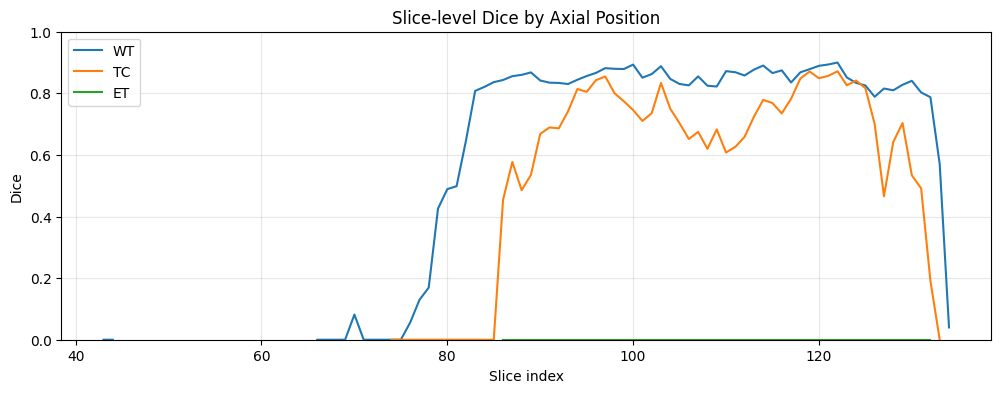

Slices containing WT: 69


In [47]:

# Cell 35 - Evaluate all slices of one validation patient

import torch
import matplotlib.pyplot as plt

patient_id = sample_visual["patient_id"]

patient_dataset = BraTSAxialSliceDataset(
    archive_path=BRATS_ZIP,
    manifest_path=MANIFEST_PATH,
    split="validation",
    inspection_config=loader_config,
    slice_indices=list(range(155)),
    max_cached_patients=1,
)

patient_indices = [
    i for i, pid in enumerate(patient_dataset.patient_ids)
    if pid == patient_id
]

assert len(patient_indices) == 1
patient_start = patient_indices[0] * 155

results = []

trained_model.eval()

with torch.inference_mode():
    for offset in range(155):
        item = patient_dataset[patient_start + offset]

        image = item["image"].unsqueeze(0).cuda()
        gt = item["target"].bool()

        probs = torch.sigmoid(trained_model(image))
        pred = (probs[0].cpu() >= 0.5)

        scores = []

        for c in range(3):
            intersection = (gt[c] & pred[c]).sum().item()
            denominator = gt[c].sum().item() + pred[c].sum().item()

            scores.append(
                2 * intersection / denominator
                if denominator > 0 else float("nan")
            )

        results.append({
            "slice": item["slice_index"],
            "WT": scores[0],
            "TC": scores[1],
            "ET": scores[2],
            "WT_pixels": int(gt[0].sum()),
        })

print("Patient:", patient_id)
print("Slices evaluated:", len(results))

fig, ax = plt.subplots(figsize=(12, 4))

for region in ["WT", "TC", "ET"]:
    ax.plot(
        [r["slice"] for r in results],
        [r[region] for r in results],
        label=region
    )

ax.set_title("Slice-level Dice by Axial Position")
ax.set_xlabel("Slice index")
ax.set_ylabel("Dice")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print("Slices containing WT:",
      sum(r["WT_pixels"] > 0 for r in results))


# Cell 36 - Investigate enhancing tumor performance


In [48]:

# Cell 36 - Investigate enhancing tumor performance

import numpy as np

patient_start = list(patient_dataset.patient_ids).index(patient_id) * 155

et_ground_truth = []
et_predictions = []

trained_model.eval()

with torch.inference_mode():
    for offset in range(155):
        item = patient_dataset[patient_start + offset]

        image = item["image"].unsqueeze(0).cuda()
        gt = item["target"][2]

        probabilities = torch.sigmoid(trained_model(image))
        pred = probabilities[0, 2].cpu() >= 0.5

        et_ground_truth.append(int(gt.sum()))
        et_predictions.append(int(pred.sum()))

print("Patient:", patient_id)
print("Slices with ET ground truth:",
      sum(x > 0 for x in et_ground_truth))
print("Slices with predicted ET:",
      sum(x > 0 for x in et_predictions))

print("Total ground-truth ET pixels:", sum(et_ground_truth))
print("Total predicted ET pixels:", sum(et_predictions))

print("Maximum ground-truth ET pixels in a slice:",
      max(et_ground_truth))
print("Maximum predicted ET pixels in a slice:",
      max(et_predictions))


Patient: BraTS-GLI-01510-000
Slices with ET ground truth: 0
Slices with predicted ET: 47
Total ground-truth ET pixels: 0
Total predicted ET pixels: 52011
Maximum ground-truth ET pixels in a slice: 0
Maximum predicted ET pixels in a slice: 1766


# Cell 37 - Analyze false-positive enhancing tumor predictions


Patient: BraTS-GLI-01510-000
ET ground-truth total: 0
ET predicted total: 52011
False-positive slice count: 47

First false-positive slice: 86
Last false-positive slice: 132

Worst false-positive slice: 96
Predicted ET pixels: 1766


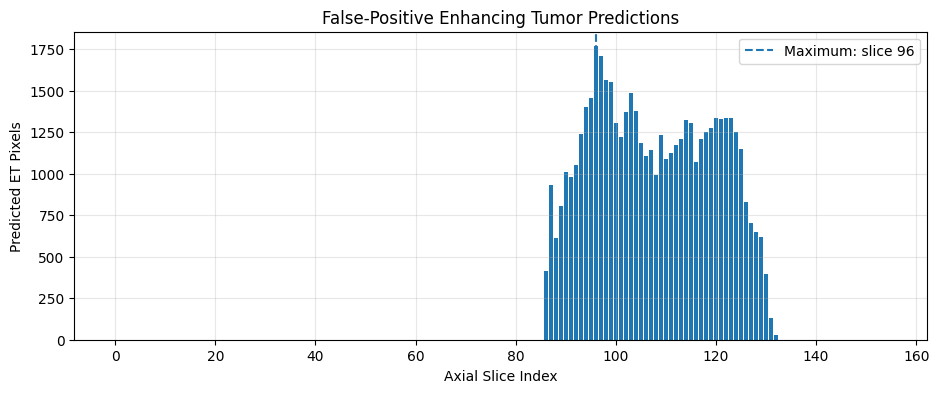

In [49]:

# Cell 37 - Analyze false-positive enhancing tumor predictions

import numpy as np
import matplotlib.pyplot as plt

counts = np.array(et_predictions)

false_positive_slices = np.flatnonzero(counts > 0)
worst_slice = int(np.argmax(counts))

print("Patient:", patient_id)
print("ET ground-truth total:", sum(et_ground_truth))
print("ET predicted total:", counts.sum())
print("False-positive slice count:", len(false_positive_slices))

print("\nFirst false-positive slice:",
      int(false_positive_slices[0]))
print("Last false-positive slice:",
      int(false_positive_slices[-1]))

print("\nWorst false-positive slice:", worst_slice)
print("Predicted ET pixels:", int(counts[worst_slice]))

plt.figure(figsize=(11, 4))
plt.bar(range(155), counts)
plt.axvline(worst_slice, linestyle="--",
            label=f"Maximum: slice {worst_slice}")
plt.title("False-Positive Enhancing Tumor Predictions")
plt.xlabel("Axial Slice Index")
plt.ylabel("Predicted ET Pixels")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Cell 38 - Inspect worst ET false-positive slice


In [50]:

# Cell 38 - Inspect worst ET false-positive slice

import matplotlib.pyplot as plt
import torch

item = patient_dataset[patient_start + worst_slice]

image = item["image"].unsqueeze(0).cuda()
ground_truth = item["target"].cpu()

trained_model.eval()

with torch.inference_mode():
    probabilities = torch.sigmoid(trained_model(image))[0].cpu()

prediction = probabilities >= 0.5

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

modalities = ["T1", "T1ce", "T2", "FLAIR"]

for i in range(4):
    axes[0, i].imshow(item["image"][i], cmap="gray")
    axes[0, i].set_title(modalities[i])
    axes[0, i].axis("off")

axes[1, 0].imshow(ground_truth[0], cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Ground Truth — WT")

axes[1, 1].imshow(ground_truth[1], cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Ground Truth — TC")

axes[1, 2].imshow(prediction[2], cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("False-Positive ET")

axes[1, 3].imshow(probabilities[2], cmap="viridis", vmin=0, vmax=1)
axes[1, 3].set_title("ET Probability")

for ax in axes[1]:
    ax.axis("off")

plt.suptitle(
    f"{patient_id} — Slice {worst_slice}"
)
plt.tight_layout()
plt.show()

print("Ground-truth ET pixels:", int(ground_truth[2].sum()))
print("Predicted ET pixels:", int(prediction[2].sum()))
print("Maximum ET probability:", float(probabilities[2].max()))


Ground-truth ET pixels: 0
Predicted ET pixels: 1766
Maximum ET probability: 0.997606635093689


# Cell 39 - Quantify false-positive ET overlap


In [51]:

# Cell 39 - Quantify false-positive ET overlap

wt_gt = ground_truth[0].bool()
tc_gt = ground_truth[1].bool()
et_pred = prediction[2].bool()

total_et = int(et_pred.sum())
inside_tc = int((et_pred & tc_gt).sum())
inside_wt = int((et_pred & wt_gt).sum())
outside_wt = int((et_pred & ~wt_gt).sum())

print("False-positive ET pixels:", total_et)
print("ET pixels inside ground-truth TC:", inside_tc)
print("ET pixels inside ground-truth WT:", inside_wt)
print("ET pixels outside ground-truth WT:", outside_wt)

if total_et > 0:
    print(
        "Percentage inside TC:",
        f"{100 * inside_tc / total_et:.2f}%"
    )
    print(
        "Percentage inside WT:",
        f"{100 * inside_wt / total_et:.2f}%"
    )
    print(
        "Percentage outside WT:",
        f"{100 * outside_wt / total_et:.2f}%"
    )


False-positive ET pixels: 1766
ET pixels inside ground-truth TC: 1565
ET pixels inside ground-truth WT: 1756
ET pixels outside ground-truth WT: 10
Percentage inside TC: 88.62%
Percentage inside WT: 99.43%
Percentage outside WT: 0.57%


# Cell 40 - Per-patient enhancing tumor evaluation


In [52]:

# Cell 40 - Per-patient enhancing tumor evaluation

import torch

validation_patients = checkpoint["dataset_metadata"]["validation_patients"]
trained_model.eval()

print(f"{'Patient':<24} {'GT ET':>10} {'Pred ET':>10} {'ET Dice':>12}")
print("-" * 62)

with torch.inference_mode():
    for pid in validation_patients:
        idx = list(patient_dataset.patient_ids).index(pid)
        start = idx * 155

        gt_total = 0
        pred_total = 0
        intersection_total = 0

        for offset in range(155):
            item = patient_dataset[start + offset]

            img = item["image"].unsqueeze(0).cuda()
            gt = item["target"][2].bool()

            probs = torch.sigmoid(trained_model(img))
            pred = probs[0, 2].cpu() >= 0.5

            gt_total += int(gt.sum())
            pred_total += int(pred.sum())
            intersection_total += int((gt & pred).sum())

        if gt_total == 0:
            dice_text = "N/A (no GT)"
        else:
            dice = 2 * intersection_total / (gt_total + pred_total)
            dice_text = f"{dice:.4f}"

        print(f"{pid:<24} {gt_total:>10} {pred_total:>10} {dice_text:>12}")


Patient                       GT ET    Pred ET      ET Dice
--------------------------------------------------------------
BraTS-GLI-01510-000               0      52011  N/A (no GT)
BraTS-GLI-01032-000           73389      78735       0.8465
BraTS-GLI-00804-000           53166      77603       0.6891
BraTS-GLI-01352-000            9409       3659       0.3099


# Cell 41 - Examine ET representation in pilot training patients


In [53]:

# Cell 41 - Examine ET representation in pilot training patients

from cap6411_atm.data.dataset import BraTSAxialSliceDataset

pilot_train_ids = checkpoint["dataset_metadata"]["train_patients"]

train_full_slices = BraTSAxialSliceDataset(
    archive_path=BRATS_ZIP,
    manifest_path=MANIFEST_PATH,
    split="train",
    inspection_config=loader_config,
    slice_indices=list(range(155)),
    cache_dir="/content/brats_cache/train",
    max_cached_patients=1,
)

patient_positions = {
    pid: i for i, pid in enumerate(train_full_slices.patient_ids)
}

print(f"{'Patient':<25} {'ET pixels':>12} {'ET slices':>12}")
print("-" * 52)

patients_without_et = 0

for pid in pilot_train_ids:
    start = patient_positions[pid] * 155
    total_et = 0
    slices_with_et = 0

    for offset in range(155):
        item = train_full_slices[start + offset]
        count = int(item["target"][2].sum())

        total_et += count
        slices_with_et += (count > 0)

    if total_et == 0:
        patients_without_et += 1

    print(f"{pid:<25} {total_et:>12} {slices_with_et:>12}")

print()
print("Training patients:", len(pilot_train_ids))
print("Patients with no ET:", patients_without_et)


Patient                      ET pixels    ET slices
----------------------------------------------------
BraTS-GLI-01368-000              16834           38
BraTS-GLI-00568-000              42721           81
BraTS-GLI-00530-000               2769           24
BraTS-GLI-00502-001              33106           37
BraTS-GLI-01423-000               4678           23
BraTS-GLI-01535-000                  0            0
BraTS-GLI-00052-000              49797           55
BraTS-GLI-00347-000              20640           50

Training patients: 8
Patients with no ET: 1


# Cell 42 - Prepare expanded pilot configuration


In [54]:

# Cell 42 - Prepare expanded pilot configuration

import json
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")

original_path = (
    repo / "configs/brats2023_gli_baseline_training.json"
)

expanded_path = (
    repo / "configs/brats2023_gli_expanded_pilot.json"
)

config = json.loads(original_path.read_text())

config.update({
    "experiment_name": "dinov3_vitb16_brats_pilot32",
    "pilot_enabled": True,
    "pilot_train_patients": 32,
    "pilot_validation_patients": 8,
    "epochs": 15,
    "batch_size": 2,
    "resume_checkpoint": None,
})

assert config["experiment_name"] != "dinov3_vitb16_brats_baseline"
assert config["pilot_enabled"]
assert config["resume_checkpoint"] is None

expanded_path.write_text(json.dumps(config, indent=2))

print("Expanded configuration:", expanded_path)
print("Experiment:", config["experiment_name"])
print("Training patients:", config["pilot_train_patients"])
print("Validation patients:", config["pilot_validation_patients"])
print("Epochs:", config["epochs"])
print("Batch size:", config["batch_size"])
print("Original checkpoint preserved: Yes")


Expanded configuration: /content/CAP6411-Adaptive-Token-Merging/configs/brats2023_gli_expanded_pilot.json
Experiment: dinov3_vitb16_brats_pilot32
Training patients: 32
Validation patients: 8
Epochs: 15
Batch size: 2
Original checkpoint preserved: Yes


# Cell 43 - Run expanded 32-patient pilot training


In [55]:

# Cell 43 - Run expanded 32-patient pilot training

import subprocess
import sys
import time
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config_path = repo / "configs/brats2023_gli_expanded_pilot.json"

assert config_path.is_file()

command = [
    sys.executable,
    "-u",
    "-m", "cap6411_atm.training.baseline",
    "--config", str(config_path),
]

print("Starting expanded BraTS pilot...", flush=True)
print("Training: 32 patients", flush=True)
print("Validation: 8 patients", flush=True)
print("Epochs: 15", flush=True)

start = time.time()

process = subprocess.Popen(
    command,
    cwd=str(repo),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="", flush=True)

exit_code = process.wait()

print("\nExit code:", exit_code)
print("Elapsed minutes:", round((time.time() - start) / 60, 2))

assert exit_code == 0, "Expanded pilot training failed"

print("Expanded pilot training completed successfully!")


Starting expanded BraTS pilot...
Training: 32 patients
Validation: 8 patients
Epochs: 15
{"epoch": 0, "metrics_scope": "deterministic_patient_subset", "pilot_metrics": true, "scope": "pilot", "train": {"batches": 2496, "bce_loss": 0.02229196156038509, "dice_loss": 0.7270935623636169, "elapsed_seconds": 299.4698611859985, "estimated_full_epoch_seconds": 8197.98744996671, "loss": 0.3746927618544789, "samples": 4960, "samples_per_second": 16.562601593218027}, "validation": {"all_empty": {"ET": false, "TC": false, "WT": false}, "batches": 624, "dice": {"ET": 0.5065016365880269, "TC": 0.6221939990474679, "WT": 0.6872231700628147}, "elapsed_seconds": 42.12153978999959, "estimated_full_epoch_seconds": 984.5909925912404, "loss": 0.43325973893365555, "macro_dice": 0.6053062685661031, "prediction_voxels": {"ET": 307232, "TC": 305597, "WT": 529793}, "samples": 1240, "samples_per_second": 29.438619912332793, "target_voxels": {"ET": 195949, "TC": 324303, "WT": 921459}}}
{"epoch": 1, "metrics_scope"

# Cell 44 - Verify expanded pilot best checkpoint


In [57]:

# Cell 44 - Verify expanded pilot best checkpoint

import json
import torch
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_brats_pilot32"
)

history = json.loads(
    (output_dir / "history.json").read_text()
)

best = max(
    history,
    key=lambda h: h["validation"]["macro_dice"]
)

best_checkpoint = torch.load(
    output_dir / "best.pt",
    map_location="cpu",
    weights_only=False
)

print("Recorded epochs:", len(history))
print("Best epoch:", best["epoch"] + 1)
print("Best macro Dice:", best["validation"]["macro_dice"])
print("Checkpoint epoch:", best_checkpoint["epoch"] + 1)
print("Checkpoint best Dice:", best_checkpoint["best_macro_dice"])

print("\nTraining patients:",
      best_checkpoint["dataset_metadata"]["train_patient_count"])
print("Validation patients:",
      best_checkpoint["dataset_metadata"]["validation_patient_count"])

assert len(history) == 15
assert best_checkpoint["epoch"] == best["epoch"]
assert abs(
    best_checkpoint["best_macro_dice"]
    - best["validation"]["macro_dice"]
) < 1e-6

print("\nExpanded pilot best checkpoint verified!")


Recorded epochs: 15
Best epoch: 7
Best macro Dice: 0.7720586394549658
Checkpoint epoch: 7
Checkpoint best Dice: 0.7720586394549658

Training patients: 32
Validation patients: 8

Expanded pilot best checkpoint verified!


# Cell 45 - Verify shared validation comparison setup


In [58]:

# Cell 45 - Verify shared validation comparison setup

import torch
from pathlib import Path

base_dir = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints"
)

pilot8 = torch.load(
    base_dir / "dinov3_vitb16_brats_baseline/best.pt",
    map_location="cpu",
    weights_only=False
)

pilot32 = torch.load(
    base_dir / "dinov3_vitb16_brats_pilot32/best.pt",
    map_location="cpu",
    weights_only=False
)

train8 = set(pilot8["dataset_metadata"]["train_patients"])
train32 = set(pilot32["dataset_metadata"]["train_patients"])

val8 = set(pilot8["dataset_metadata"]["validation_patients"])
val32 = set(pilot32["dataset_metadata"]["validation_patients"])

print("Original pilot training patients:", len(train8))
print("Expanded pilot training patients:", len(train32))
print("Original pilot validation patients:", len(val8))
print("Expanded pilot validation patients:", len(val32))

print("\nShared validation patients:", len(val8 & val32))
print("Training/validation leakage:",
      bool((train8 | train32) & (val8 | val32)))

assert not ((train8 | train32) & (val8 | val32))

print("\nExpanded pilot validation patient IDs:")
for pid in sorted(val32):
    print(pid)

print("\nBoth models can be evaluated on the same 8 patients.")


Original pilot training patients: 8
Expanded pilot training patients: 32
Original pilot validation patients: 4
Expanded pilot validation patients: 8

Shared validation patients: 4
Training/validation leakage: False

Expanded pilot validation patient IDs:
BraTS-GLI-00131-000
BraTS-GLI-00804-000
BraTS-GLI-00805-000
BraTS-GLI-01020-000
BraTS-GLI-01032-000
BraTS-GLI-01352-000
BraTS-GLI-01363-000
BraTS-GLI-01510-000

Both models can be evaluated on the same 8 patients.


# Cell 46 - Fair comparison of both trained checkpoints


In [59]:

# Cell 46 - Fair comparison of both trained checkpoints

import torch
import gc
from cap6411_atm.data.dataset import BraTSAxialSliceDataset
from cap6411_atm.training.metrics import StreamingDice

comparison_patients = sorted(val32)
regions = ["WT", "TC", "ET"]

comparison_dataset = BraTSAxialSliceDataset(
    archive_path=BRATS_ZIP,
    manifest_path=MANIFEST_PATH,
    split="validation",
    inspection_config=loader_config,
    slice_indices=list(range(155)),
    cache_dir="/content/brats_cache/comparison",
    max_cached_patients=1,
)

patient_positions = {
    pid: i
    for i, pid in enumerate(comparison_dataset.patient_ids)
}

def evaluate_checkpoint(ckpt, name):
    trained_model.load_state_dict(
        ckpt["model_state"],
        strict=True
    )
    trained_model.eval()

    # Accumulate cohort-level intersections and volumes.
    intersections = torch.zeros(3, dtype=torch.float64)
    predictions = torch.zeros(3, dtype=torch.float64)
    targets = torch.zeros(3, dtype=torch.float64)

    with torch.inference_mode():
        for n, pid in enumerate(comparison_patients, 1):
            start = patient_positions[pid] * 155

            for offset in range(155):
                item = comparison_dataset[start + offset]

                img = item["image"].unsqueeze(0).cuda()
                gt = item["target"].bool()

                logits = trained_model(img)
                pred = (torch.sigmoid(logits)[0].cpu() >= 0.5)

                intersections += (
                    (pred & gt).sum(dim=(1, 2)).double()
                )
                predictions += pred.sum(dim=(1, 2)).double()
                targets += gt.sum(dim=(1, 2)).double()

            print(f"{name}: evaluated {n}/8 patients", flush=True)

    denominators = predictions + targets
    dice = torch.where(
        denominators > 0,
        2 * intersections / denominators.clamp_min(1),
        torch.ones_like(denominators)
    )

    result = {
        region: float(dice[i])
        for i, region in enumerate(regions)
    }
    result["macro"] = float(dice.mean())

    return result

results = {}

for ckpt, name in [
    (pilot8, "Original 8-patient pilot"),
    (pilot32, "Expanded 32-patient pilot"),
]:
    results[name] = evaluate_checkpoint(ckpt, name)

print("\n=== SAME-PATIENT VALIDATION COMPARISON ===")
print(f"{'Model':<28} {'WT':>8} {'TC':>8} {'ET':>8} {'Macro':>8}")

for name, scores in results.items():
    print(
        f"{name:<28} "
        f"{scores['WT']:>8.4f} "
        f"{scores['TC']:>8.4f} "
        f"{scores['ET']:>8.4f} "
        f"{scores['macro']:>8.4f}"
    )

print("\nEvaluation complete. No model weights were updated.")


Original 8-patient pilot: evaluated 1/8 patients
Original 8-patient pilot: evaluated 2/8 patients
Original 8-patient pilot: evaluated 3/8 patients
Original 8-patient pilot: evaluated 4/8 patients
Original 8-patient pilot: evaluated 5/8 patients
Original 8-patient pilot: evaluated 6/8 patients
Original 8-patient pilot: evaluated 7/8 patients
Original 8-patient pilot: evaluated 8/8 patients
Expanded 32-patient pilot: evaluated 1/8 patients
Expanded 32-patient pilot: evaluated 2/8 patients
Expanded 32-patient pilot: evaluated 3/8 patients
Expanded 32-patient pilot: evaluated 4/8 patients
Expanded 32-patient pilot: evaluated 5/8 patients
Expanded 32-patient pilot: evaluated 6/8 patients
Expanded 32-patient pilot: evaluated 7/8 patients
Expanded 32-patient pilot: evaluated 8/8 patients

=== SAME-PATIENT VALIDATION COMPARISON ===
Model                              WT       TC       ET    Macro
Original 8-patient pilot       0.8514   0.7339   0.5730   0.7194
Expanded 32-patient pilot      0.8

# Cell 47 - Compare ET false positives on the ET-negative patient


In [60]:

# Cell 47 - Compare ET false positives on the ET-negative patient

import torch

patient_id = "BraTS-GLI-01510-000"
start = patient_positions[patient_id] * 155

for name, ckpt in [
    ("Original 8-patient model", pilot8),
    ("Expanded 32-patient model", pilot32),
]:
    trained_model.load_state_dict(
        ckpt["model_state"],
        strict=True
    )
    trained_model.eval()

    gt_total = 0
    predicted_total = 0
    false_positive_slices = 0

    with torch.inference_mode():
        for offset in range(155):
            item = comparison_dataset[start + offset]

            image = item["image"].unsqueeze(0).cuda()
            gt = item["target"][2].bool()

            probabilities = torch.sigmoid(
                trained_model(image)
            )[0, 2].cpu()

            pred = probabilities >= 0.5

            gt_total += int(gt.sum())
            predicted_total += int(pred.sum())

            if pred.any():
                false_positive_slices += 1

    print(f"\n{name}")
    print("Ground-truth ET pixels:", gt_total)
    print("Predicted ET pixels:", predicted_total)
    print("Slices with predicted ET:", false_positive_slices)

print("\nComparison complete.")



Original 8-patient model
Ground-truth ET pixels: 0
Predicted ET pixels: 52011
Slices with predicted ET: 47

Expanded 32-patient model
Ground-truth ET pixels: 0
Predicted ET pixels: 17878
Slices with predicted ET: 49

Comparison complete.


# Cell 48 - Save baseline comparison results


In [61]:

# Cell 48 - Save baseline comparison results

import json
from pathlib import Path
from datetime import datetime, timezone

report = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "BraTS 2023 Adult Glioma",
    "model": "DINOv3 ViT-B/16",
    "evaluation": {
        "scope": "8 shared validation patients",
        "slices": 1240,
        "threshold": 0.5,
        "test_split_used": False,
        "independent_test": False,
    },
    "original_pilot": {
        "training_patients": 8,
        "best_epoch": 15,
        "dice": results["Original 8-patient pilot"],
        "et_negative_patient_false_positive_pixels": 52011,
    },
    "expanded_pilot": {
        "training_patients": 32,
        "best_epoch": 7,
        "dice": results["Expanded 32-patient pilot"],
        "et_negative_patient_false_positive_pixels": 17878,
    },
}

report_path = Path(
    "/content/drive/MyDrive/CAP6411/"
    "baseline_comparison_report.json"
)

report_path.write_text(json.dumps(report, indent=2))

print("Report saved:", report_path)
print("Original macro Dice:",
      report["original_pilot"]["dice"]["macro"])
print("Expanded macro Dice:",
      report["expanded_pilot"]["dice"]["macro"])
print("Test split untouched:",
      not report["evaluation"]["test_split_used"])


Report saved: /content/drive/MyDrive/CAP6411/baseline_comparison_report.json
Original macro Dice: 0.7194344671023335
Expanded macro Dice: 0.7720381378263307
Test split untouched: True


# Cell 49 - Verify Workstream 1 handoff files


In [63]:

# Cell 49 - Verify Workstream 1 handoff files

from pathlib import Path

drive_root = Path("/content/drive/MyDrive/CAP6411")
repo_root = Path("/content/CAP6411-Adaptive-Token-Merging")

required_files = {
    "BraTS dataset ZIP": drive_root / "datasets/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData.zip",
    "Patient split manifest": drive_root / "brats2023_gli_split_seed42.json",
    "Original best checkpoint": drive_root / "checkpoints/dinov3_vitb16_brats_baseline/best.pt",
    "Expanded best checkpoint": drive_root / "checkpoints/dinov3_vitb16_brats_pilot32/best.pt",
    "Comparison report": drive_root / "baseline_comparison_report.json",
    "Model configuration": repo_root / "configs/dinov3_vitb16_brats.json",
    "Training implementation": repo_root / "src/cap6411_atm/training/baseline.py",
}

all_present = True

for name, path in required_files.items():
    exists = path.is_file()
    all_present &= exists
    print(f"{'PASS' if exists else 'MISSING'} - {name}")

print()
print("All required files present:", all_present)
assert all_present


PASS - BraTS dataset ZIP
PASS - Patient split manifest
PASS - Original best checkpoint
PASS - Expanded best checkpoint
PASS - Comparison report
PASS - Model configuration
PASS - Training implementation

All required files present: True


# Cell 50 - Prepare full-cohort training configuration


In [64]:

# Cell 50 - Prepare full-cohort training configuration

import json
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")

source = repo / "configs/brats2023_gli_baseline_training.json"
destination = repo / "configs/brats2023_gli_full_training.json"

config = json.loads(source.read_text())

config.update({
    "experiment_name": "dinov3_vitb16_brats_full",
    "pilot_enabled": False,
    "epochs": 30,
    "batch_size": 2,
    "resume_checkpoint": None,
})

destination.write_text(json.dumps(config, indent=2))

print("Configuration:", destination)
print("Experiment:", config["experiment_name"])
print("Full cohort enabled:", not config["pilot_enabled"])
print("Configured epochs:", config["epochs"])
print("Checkpoint directory:",
      Path(config["output_dir"]) / config["experiment_name"])

assert config["pilot_enabled"] is False
assert config["resume_checkpoint"] is None

print("Full-cohort configuration ready!")
print("No training started.")


Configuration: /content/CAP6411-Adaptive-Token-Merging/configs/brats2023_gli_full_training.json
Experiment: dinov3_vitb16_brats_full
Full cohort enabled: True
Configured epochs: 30
Checkpoint directory: /content/drive/MyDrive/CAP6411/checkpoints/dinov3_vitb16_brats_full
Full-cohort configuration ready!
No training started.


# Cell 51 - Full-cohort training preflight


In [65]:

# Cell 51 - Full-cohort training preflight

import json
import torch
import shutil
from pathlib import Path

config_path = (
    Path("/content/CAP6411-Adaptive-Token-Merging")
    / "configs/brats2023_gli_full_training.json"
)

config = json.loads(config_path.read_text())

output_dir = (
    Path(config["output_dir"]) / config["experiment_name"]
)

gpu_available = torch.cuda.is_available()

print("GPU available:", gpu_available)

if gpu_available:
    print("GPU:", torch.cuda.get_device_name(0))
    free, total = torch.cuda.mem_get_info()
    print("Free GPU memory (GiB):", round(free / 2**30, 2))
    print("Total GPU memory (GiB):", round(total / 2**30, 2))

disk = shutil.disk_usage("/content")

print("\nAvailable local disk (GiB):",
      round(disk.free / 2**30, 2))

print("\nTraining patients: 876")
print("Validation patients: 187")
print("Training slices:", 876 * 155)
print("Validation slices:", 187 * 155)

print("\nConfigured epochs:", config["epochs"])
print("Batch size:", config["batch_size"])
print("AMP:", config["amp"])
print("Experiment:", config["experiment_name"])

print("\nExisting full-run checkpoints:")
for filename in ["last.pt", "best.pt", "history.json"]:
    path = output_dir / filename
    print(filename, "EXISTS" if path.exists() else "not created")

assert gpu_available, "GPU is required for this experiment"
assert config["pilot_enabled"] is False

print("\nPreflight checks passed. No training started.")


GPU available: True
GPU: Tesla T4
Free GPU memory (GiB): 13.98
Total GPU memory (GiB): 14.56

Available local disk (GiB): 89.5

Training patients: 876
Validation patients: 187
Training slices: 135780
Validation slices: 28985

Configured epochs: 30
Batch size: 2
AMP: True
Experiment: dinov3_vitb16_brats_full

Existing full-run checkpoints:
last.pt not created
best.pt not created
history.json not created

Preflight checks passed. No training started.


# Cell 52 - Train one full-cohort epoch


In [ ]:

# Cell 52 - Train one full-cohort epoch

import json
import subprocess
import sys
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config_path = repo / "configs/brats2023_gli_full_training.json"

config = json.loads(config_path.read_text())

# Start with one full epoch.
config["epochs"] = 1
config_path.write_text(json.dumps(config, indent=2))

assert config["pilot_enabled"] is False
assert config["epochs"] == 1
assert config["resume_checkpoint"] is None

print("Starting first FULL-COHORT epoch", flush=True)
print("Training patients: 876", flush=True)
print("Validation patients: 187", flush=True)
print("Epochs this run: 1", flush=True)

process = subprocess.Popen(
    [
        sys.executable, "-u",
        "-m", "cap6411_atm.training.baseline",
        "--config", str(config_path),
    ],
    cwd=str(repo),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="", flush=True)

exit_code = process.wait()

print("Exit code:", exit_code)
assert exit_code == 0, "Full-cohort epoch failed"

print("First full-cohort epoch completed!")


Starting first FULL-COHORT epoch
Training patients: 876
Validation patients: 187
Epochs this run: 1


In [1]:

# Cell 53 - Diagnose interrupted full-cohort training

from pathlib import Path
import shutil

print("=== DISK ===")
disk = shutil.disk_usage("/content")
print("Used GiB:", round(disk.used / 2**30, 2))
print("Free GiB:", round(disk.free / 2**30, 2))

print("\n=== MRI CACHE ===")
cache = Path("/content/brats_cache")

if cache.exists():
    for folder in sorted(cache.iterdir()):
        if folder.is_dir():
            size = sum(
                f.stat().st_size
                for f in folder.rglob("*")
                if f.is_file()
            )
            print(folder.name, round(size / 2**30, 2), "GiB")
else:
    print("Cache directory not present")

print("\n=== FULL-COHORT CHECKPOINTS ===")
output = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "dinov3_vitb16_brats_full"
)

for name in ["last.pt", "best.pt", "history.json"]:
    path = output / name
    print(name, "EXISTS" if path.is_file() else "NOT FOUND")


=== DISK ===
Used GiB: 0.08
Free GiB: 112.54

=== MRI CACHE ===
Cache directory not present

=== FULL-COHORT CHECKPOINTS ===
last.pt NOT FOUND
best.pt NOT FOUND
history.json NOT FOUND


In [2]:

# Cell 54 - Restore Drive and inspect persistent project files

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

root = Path("/content/drive/MyDrive/CAP6411")

paths = {
    "BraTS dataset": root / "datasets/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData.zip",
    "Patient manifest": root / "brats2023_gli_split_seed42.json",
    "Original pilot checkpoint": root / "checkpoints/dinov3_vitb16_brats_baseline/best.pt",
    "Expanded pilot checkpoint": root / "checkpoints/dinov3_vitb16_brats_pilot32/best.pt",
    "Full-cohort last checkpoint": root / "checkpoints/dinov3_vitb16_brats_full/last.pt",
    "Full-cohort best checkpoint": root / "checkpoints/dinov3_vitb16_brats_full/best.pt",
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'NOT FOUND'}")

print("\nLocal repository:",
      Path("/content/CAP6411-Adaptive-Token-Merging").exists())

print("Official DINOv3 source:",
      Path("/content/dinov3").exists())


Mounted at /content/drive
BraTS dataset: FOUND
Patient manifest: FOUND
Original pilot checkpoint: FOUND
Expanded pilot checkpoint: FOUND
Full-cohort last checkpoint: NOT FOUND
Full-cohort best checkpoint: NOT FOUND

Local repository: False
Official DINOv3 source: False


In [3]:

# Cell 55 - Restore repositories after Colab reset

from pathlib import Path
import subprocess

REPO_ROOT = Path("/content/CAP6411-Adaptive-Token-Merging")
DINO_ROOT = Path("/content/dinov3")

PROJECT_COMMIT = "38e31821b7256c3b8576322d6486a1a11302fbfd"
DINO_COMMIT = "6876159a11b4df116f30f667f8c9888617df0751"

repositories = [
    (
        REPO_ROOT,
        "https://github.com/FaramarzAboutalebi/CAP6411-Adaptive-Token-Merging.git",
        PROJECT_COMMIT,
    ),
    (
        DINO_ROOT,
        "https://github.com/facebookresearch/dinov3.git",
        DINO_COMMIT,
    ),
]

for path, url, commit in repositories:
    if not path.exists():
        subprocess.run(
            ["git", "clone", url, str(path)],
            check=True
        )

    subprocess.run(
        ["git", "-C", str(path), "checkout", "--detach", commit],
        check=True
    )

    actual = subprocess.check_output(
        ["git", "-C", str(path), "rev-parse", "HEAD"],
        text=True
    ).strip()

    assert actual == commit
    print(f"Verified: {path.name}")
    print(f"Commit: {actual}\n")

print("Both repositories restored successfully!")


Verified: CAP6411-Adaptive-Token-Merging
Commit: 38e31821b7256c3b8576322d6486a1a11302fbfd

Verified: dinov3
Commit: 6876159a11b4df116f30f667f8c9888617df0751

Both repositories restored successfully!


In [4]:

# Cell 56 - Update Colab to the disk-cache fix

from pathlib import Path
import subprocess
import json

REPO_ROOT = Path("/content/CAP6411-Adaptive-Token-Merging")

EXPECTED_COMMIT = "0290c10792b56c35c1536f4443e6cda2b7948542"

subprocess.run(
    [
        "git", "-C", str(REPO_ROOT),
        "fetch", "origin", "feature/brats-dataset-inspection"
    ],
    check=True
)

subprocess.run(
    [
        "git", "-C", str(REPO_ROOT),
        "checkout", "--detach", EXPECTED_COMMIT
    ],
    check=True
)

actual = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"],
    text=True
).strip()

assert actual == EXPECTED_COMMIT

config_path = (
    REPO_ROOT
    / "configs/brats2023_gli_full_cohort_training.json"
)

config = json.loads(config_path.read_text())

assert config["cache_dir"] is None
assert config["pilot_enabled"] is False
assert config["epochs"] == 1
assert config["batch_size"] == 2
assert config["amp"] is True

print("Repository commit:", actual)
print("Persistent disk caching:", config["cache_dir"])
print("Training scope: Full cohort")
print("Initial epochs:", config["epochs"])
print("Output directory:",
      Path(config["output_dir"]) / config["experiment_name"])

print("\nDisk-cache fix successfully installed in repository!")


Repository commit: 0290c10792b56c35c1536f4443e6cda2b7948542
Persistent disk caching: None
Training scope: Full cohort
Initial epochs: 1
Output directory: /content/drive/MyDrive/CAP6411/checkpoints/full_cohort/dinov3_vitb16_brats_full_cohort

Disk-cache fix successfully installed in repository!


In [5]:

# Cell 57 - Restore dependencies after Colab reset

import subprocess
import sys
from pathlib import Path

REPO_ROOT = Path("/content/CAP6411-Adaptive-Token-Merging")
DINO_ROOT = Path("/content/dinov3")

assert REPO_ROOT.is_dir()
assert DINO_ROOT.is_dir()

def pip_install(*args):
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *args],
        check=True
    )

# Install project dependencies.
pip_install("-r", str(REPO_ROOT / "requirements.txt"))
pip_install("-e", str(REPO_ROOT), "--no-deps")

# Install the official DINOv3 package and dependencies.
pip_install("-e", str(DINO_ROOT), "--no-deps")
pip_install(
    "ftfy", "omegaconf", "regex",
    "scikit-learn", "submitit",
    "termcolor", "torchmetrics"
)

# Verify imports.
import torch
import cap6411_atm
from cap6411_atm.training.baseline import BaselineTrainingConfig

config = BaselineTrainingConfig.from_json(
    REPO_ROOT / "configs/brats2023_gli_full_cohort_training.json"
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Persistent disk cache:", config.cache_dir)
print("Training scope:", config.scope)
print("Configured epochs:", config.epochs)

assert torch.cuda.is_available()
assert config.cache_dir is None
assert config.scope == "full_cohort"

print("\nEnvironment restored successfully!")
print("No training started.")


ModuleNotFoundError: No module named 'cap6411_atm'

In [6]:

# Cell 58 - Diagnose and fix cap6411_atm import

import sys
import subprocess
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")

print("Repository exists:", repo.is_dir())
print("Source directory exists:", (repo / "src").is_dir())
print("Package directory exists:",
      (repo / "src/cap6411_atm").is_dir())

# Make the source package visible to the current Colab kernel.
source_path = str(repo / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)

# Also make the repo root available for project configuration imports.
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

import cap6411_atm
from cap6411_atm.training.baseline import BaselineTrainingConfig

config = BaselineTrainingConfig.from_json(
    repo / "configs/brats2023_gli_full_cohort_training.json"
)

print("\nPackage import: SUCCESS")
print("Cache directory:", config.cache_dir)
print("Training scope:", config.scope)
print("Epochs:", config.epochs)

assert config.cache_dir is None
assert config.scope == "full_cohort"

print("\nImport issue resolved. No training started.")


Repository exists: True
Source directory exists: True
Package directory exists: True

Package import: SUCCESS
Cache directory: None
Training scope: full_cohort
Epochs: 1

Import issue resolved. No training started.


In [7]:

# Cell 59 - Final preflight before restarting training

import json
import os
import shutil
import subprocess
import sys
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config_path = repo / "configs/brats2023_gli_full_cohort_training.json"
config = json.loads(config_path.read_text())

# Verify subprocess imports independently of the notebook.
env = os.environ.copy()
env["PYTHONPATH"] = str(repo / "src") + os.pathsep + env.get("PYTHONPATH", "")

result = subprocess.run(
    [
        sys.executable,
        "-c",
        "import cap6411_atm; "
        "from cap6411_atm.training.baseline import BaselineTrainingConfig; "
        "import torch; "
        "print('Subprocess import: SUCCESS'); "
        "print('CUDA available:', torch.cuda.is_available()); "
        "print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None')"
    ],
    cwd=str(repo),
    env=env,
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
assert result.returncode == 0

# Verify persistent inputs.
for name, value in [
    ("BraTS archive", config["archive_path"]),
    ("Patient manifest", config["manifest_path"]),
    ("Pretrained DINOv3 weights", config["checkpoint_path"]),
    ("DINOv3 source", config["dinov3_repository"]),
]:
    path = Path(value)
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    assert exists, f"Missing: {path}"

# Verify storage-safe configuration.
assert config["cache_dir"] is None
assert config["pilot_enabled"] is False
assert config["epochs"] == 1

disk = shutil.disk_usage("/content")
print("\nFree local disk (GiB):", round(disk.free / 2**30, 2))
print("Persistent disk cache:", config["cache_dir"])
print("Training patients: 876")
print("Validation patients: 187")
print("Epochs:", config["epochs"])

print("\nFinal preflight PASSED. No training started.")


Subprocess import: SUCCESS
CUDA available: True
GPU: Tesla T4

BraTS archive: FOUND
Patient manifest: FOUND
Pretrained DINOv3 weights: FOUND
DINOv3 source: FOUND

Free local disk (GiB): 112.45
Persistent disk cache: None
Training patients: 876
Validation patients: 187
Epochs: 1

Final preflight PASSED. No training started.


In [8]:

# Cell 60 - Run first storage-safe full-cohort epoch

import os
import subprocess
import sys
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config_path = repo / "configs/brats2023_gli_full_cohort_training.json"

# Ensure the subprocess can import our project.
env = os.environ.copy()
env["PYTHONPATH"] = (
    str(repo / "src")
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

print("Starting storage-safe FULL-COHORT training", flush=True)
print("Training patients: 876", flush=True)
print("Validation patients: 187", flush=True)
print("Epochs: 1", flush=True)
print("Persistent disk cache: DISABLED", flush=True)
print("Checkpoint destination: Google Drive", flush=True)

process = subprocess.Popen(
    [
        sys.executable,
        "-u",
        "-m",
        "cap6411_atm.training.baseline",
        "--config",
        str(config_path),
    ],
    cwd=str(repo),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="", flush=True)

exit_code = process.wait()

print("\nExit code:", exit_code)
assert exit_code == 0, "Full-cohort training failed"

print("First full-cohort epoch completed successfully!")


Starting storage-safe FULL-COHORT training
Training patients: 876
Validation patients: 187
Epochs: 1
Persistent disk cache: DISABLED
Checkpoint destination: Google Drive
Downloading: "file:///content/drive/MyDrive/CAP6411/checkpoints/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth

  0%|          | 0.00/327M [00:00<?, ?B/s]
  0%|          | 128k/327M [00:00<38:49, 147kB/s]
  2%|▏         | 6.12M/327M [00:00<00:38, 8.73MB/s]
  3%|▎         | 9.50M/327M [00:01<00:28, 11.7MB/s]
  4%|▎         | 12.2M/327M [00:01<00:31, 10.5MB/s]
  7%|▋         | 21.9M/327M [00:01<00:13, 24.1MB/s]
  9%|▉         | 29.8M/327M [00:01<00:09, 34.3MB/s]
 11%|█         | 35.6M/327M [00:01<00:09, 33.8MB/s]
 14%|█▍        | 45.8M/327M [00:01<00:06, 47.9MB/s]
 17%|█▋        | 56.5M/327M [00:02<00:04, 62.0MB/s]
 20%|█▉        | 64.4M/327M [00:02<00:04, 59.5MB/s]
 23%|██▎       | 73.8M/327M [00:02<00:03, 68.5MB/s]
 25%|██▍       | 81.5M/

In [9]:

# Cell 61 - Verify full-cohort checkpoint and history

from pathlib import Path
import json

output = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "full_cohort/dinov3_vitb16_brats_full_cohort"
)

for filename in ["last.pt", "best.pt", "history.json"]:
    path = output / filename
    assert path.is_file(), f"Missing: {path}"
    print(filename, "FOUND", round(path.stat().st_size / 2**20, 2), "MiB")

history = json.loads((output / "history.json").read_text())
print("\nCompleted epochs:", len(history))
print("Latest validation macro Dice:",
      history[-1]["validation"]["macro_dice"])

print("\nCheckpoint verification PASSED")


last.pt FOUND 342.12 MiB
best.pt FOUND 342.12 MiB
history.json FOUND 0.0 MiB

Completed epochs: 1
Latest validation macro Dice: 0.7941234244219583

Checkpoint verification PASSED


In [11]:

# Cell 62 - Diagnose checkpoint RNG tensor location

from pathlib import Path
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "full_cohort/dinov3_vitb16_brats_full_cohort/last.pt"
)

assert checkpoint_path.is_file()

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

rng = checkpoint["rng_state"]

print("Saved epoch index:", checkpoint["epoch"])
print("Torch RNG type:", type(rng["torch"]).__name__)
print("Torch RNG dtype:", rng["torch"].dtype)
print("Torch RNG device:", rng["torch"].device)

if rng["cuda"] is not None:
    print("CUDA RNG devices:", [
        str(state.device) for state in rng["cuda"]
    ])

print("Checkpoint inspection completed.")
print("No checkpoint files modified.")


Saved epoch index: 0
Torch RNG type: Tensor
Torch RNG dtype: torch.uint8
Torch RNG device: cpu
CUDA RNG devices: ['cpu']
Checkpoint inspection completed.
No checkpoint files modified.


In [12]:

# Cell 64 - Install the RNG restoration fix in Colab

from pathlib import Path
import subprocess
import sys

repo = Path("/content/CAP6411-Adaptive-Token-Merging")

expected_commit = "209d803078a4ed9880a72fcb792b5d82a3d94be3"

# Fetch the corrected implementation.
subprocess.run(
    [
        "git", "-C", str(repo),
        "fetch", "origin", "feature/brats-dataset-inspection"
    ],
    check=True
)

subprocess.run(
    ["git", "-C", str(repo), "checkout", "--detach", expected_commit],
    check=True
)

actual_commit = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "HEAD"],
    text=True
).strip()

assert actual_commit == expected_commit

# Verify the patched source is present.
source = (
    repo / "src/cap6411_atm/training/baseline.py"
).read_text()

assert 'torch.set_rng_state(state["torch"].cpu())' in source
assert '[rng_state.cpu() for rng_state in state["cuda"]]' in source

# Confirm the Epoch 1 checkpoint is still present.
checkpoint = Path(
    "/content/drive/MyDrive/CAP6411/checkpoints/"
    "full_cohort/dinov3_vitb16_brats_full_cohort/last.pt"
)

assert checkpoint.is_file()

print("Commit:", actual_commit)
print("CPU RNG restoration: VERIFIED")
print("CUDA RNG restoration: VERIFIED")
print("Epoch 1 checkpoint: FOUND")
print("\nRNG fix installed successfully.")
print("No training started.")


Commit: 209d803078a4ed9880a72fcb792b5d82a3d94be3
CPU RNG restoration: VERIFIED
CUDA RNG restoration: VERIFIED
Epoch 1 checkpoint: FOUND

RNG fix installed successfully.
No training started.


In [13]:

# Cell 65 - Verify checkpoint resume without training

import os
import subprocess
import sys
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")

env = os.environ.copy()
env["PYTHONPATH"] = (
    str(repo / "src")
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

verification_code = """
from pathlib import Path
from cap6411_atm.training.baseline import (
    BaselineTrainingConfig,
    build_training_components,
    resume_from_checkpoint,
)

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config = BaselineTrainingConfig.from_json(
    repo / "configs/brats2023_gli_full_cohort_training.json"
)

assert config.cache_dir is None
assert config.pilot_enabled is False

checkpoint = (
    Path(config.output_dir)
    / config.experiment_name
    / "last.pt"
)

assert checkpoint.is_file()

print("Building training components...", flush=True)
components = build_training_components(config)

print("Restoring checkpoint...", flush=True)
start_epoch, best_dice, history = resume_from_checkpoint(
    checkpoint, components, config
)

print("Resume starts at epoch index:", start_epoch)
print("Completed epochs:", len(history))
print("Best validation macro Dice:", best_dice)

assert start_epoch == 1
assert len(history) == 1
assert abs(best_dice - 0.7941234244219583) < 1e-6

print("CHECKPOINT RESUME TEST PASSED", flush=True)
print("No training performed.", flush=True)
"""

result = subprocess.run(
    [sys.executable, "-u", "-c", verification_code],
    cwd=str(repo),
    env=env,
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

assert result.returncode == 0, "Checkpoint resume test failed"


Building training components...
Restoring checkpoint...
Resume starts at epoch index: 1
Completed epochs: 1
Best validation macro Dice: 0.7941234244219583
CHECKPOINT RESUME TEST PASSED
No training performed.



In [14]:

# Cell 66 - Resume full-cohort training for Epoch 2

import json
import os
import subprocess
import sys
from pathlib import Path

repo = Path("/content/CAP6411-Adaptive-Token-Merging")
config_path = repo / "configs/brats2023_gli_full_cohort_training.json"

config = json.loads(config_path.read_text())

checkpoint = (
    Path(config["output_dir"])
    / config["experiment_name"]
    / "last.pt"
)

assert checkpoint.is_file()
assert config["cache_dir"] is None
assert config["pilot_enabled"] is False

# Epoch 1 is complete; train one additional epoch.
config["epochs"] = 2
config["resume_checkpoint"] = str(checkpoint)
config_path.write_text(json.dumps(config, indent=2))

env = os.environ.copy()
env["PYTHONPATH"] = (
    str(repo / "src")
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

print("Resuming from completed Epoch 1", flush=True)
print("Starting epoch index: 1", flush=True)
print("Target: 2 total epochs", flush=True)
print("Persistent disk cache: DISABLED", flush=True)

process = subprocess.Popen(
    [
        sys.executable, "-u", "-m",
        "cap6411_atm.training.baseline",
        "--config", str(config_path),
    ],
    cwd=str(repo),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end="", flush=True)

exit_code = process.wait()

print("\nExit code:", exit_code)
assert exit_code == 0, "Epoch 2 training failed"

print("Epoch 2 completed successfully!")


Resuming from completed Epoch 1
Starting epoch index: 1
Target: 2 total epochs
Persistent disk cache: DISABLED
{"epoch": 1, "metrics_scope": "full_train_validation_splits", "pilot_metrics": false, "scope": "full_cohort", "train": {"batches": 68328, "bce_loss": 0.008219080103433779, "dice_loss": 0.25477377748714136, "elapsed_seconds": 5190.876686974001, "estimated_full_epoch_seconds": 5190.876686974001, "loss": 0.13149642880832058, "samples": 135780, "samples_per_second": 26.157431237140862}, "validation": {"all_empty": {"ET": false, "TC": false, "WT": false}, "batches": 14586, "dice": {"ET": 0.7320681649477365, "TC": 0.856477419756448, "WT": 0.8689814228827445}, "elapsed_seconds": 671.5835571989992, "estimated_full_epoch_seconds": 671.5835571989992, "loss": 0.16067527591821004, "macro_dice": 0.819175669195643, "prediction_voxels": {"ET": 5549174, "TC": 6852521, "WT": 17147166}, "samples": 28985, "samples_per_second": 43.15918650672288, "target_voxels": {"ET": 4054765, "TC": 6673706, "W

## Completed full-cohort baseline: Epoch 2 validation results

The storage-safe full-cohort run completed two epochs using all 876 training
patients and all 187 validation patients. The isolated 188-patient test split
was not evaluated. These are global thresholded **validation** Dice values,
not test results.

| Metric | Epoch 1 | Epoch 2 |
|---|---:|---:|
| WT Dice | 0.84847853 | 0.86898142 |
| TC Dice | 0.81595193 | 0.85647742 |
| ET Dice | 0.71793982 | 0.73206816 |
| Macro Dice | 0.79412342 | 0.81917567 |

Epoch 2 was resumed from the completed Epoch 1 checkpoint. Persistent disk
caching remained disabled, and the checkpoint-resume path started at zero-based
epoch index 1 rather than repeating epoch index 0.
